In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
df_original = pd.read_csv("/content/netflix_titles.csv")

In [6]:
print("Dataset Name: Netflix Movies and TV Shows")
print("File Type: CSV")
print("Number of Rows:", df_original.shape[0])
print("Number of Columns:", df_original.shape[1])

Dataset Name: Netflix Movies and TV Shows
File Type: CSV
Number of Rows: 8807
Number of Columns: 12


In [8]:
print("First 5 Records:")
display(df_original.head())

print("Last 5 Records:")
display(df_original.tail())

First 5 Records:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


Last 5 Records:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."
8806,s8807,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,"March 2, 2019",2015,TV-14,111 min,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a ty...


In [10]:
print("Column Names:")
print(df_original.columns.tolist())

print("\nData Types:")
print(df_original.dtypes)

print("\nDataset Information:")
df_original.info()

Column Names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Data Types:
show_id         object
type            object
title           object
director        object
cast            object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
description     object
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   i

In [12]:
numerical_columns = df_original.select_dtypes(include=np.number).columns

categorical_columns = df_original.select_dtypes(
    include=['object', 'category']
).columns

print("Numerical Columns:")
print(numerical_columns.tolist())

print("\nCategorical Columns:")
print(categorical_columns.tolist())

Numerical Columns:
['release_year']

Categorical Columns:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'rating', 'duration', 'listed_in', 'description']


In [14]:
print("Numerical Summary:")
display(df_original.describe())

print("Categorical Summary:")
display(df_original.describe(include='object'))

Numerical Summary:


,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


Categorical Summary:


,show_id,type,title,director,cast,country,date_added,rating,duration,listed_in,description
count,8807,8807,8807,6173,7982,7976,8797,8803,8804,8807,8807
unique,8807,2,8807,4528,7692,748,1767,17,220,514,8775
top,s1,Movie,Dick Johnson Is Dead,Rajiv Chilaka,David Attenborough,United States,"January 1, 2020",TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,6131,1,19,19,2818,109,3207,1793,362,4


In [16]:
missing_count = df_original.isnull().sum()

misplaying_percentage = (missing_count / len(df_original)) * 100

missing_report = pd.DataFrame({
    'Missing Values': missing_count,
    'Missing Percentage': misplaying_percentage
})

display(missing_report)

,Missing Values,Missing Percentage
show_id,0,0.000000
type,0,0.000000
title,0,0.000000
director,2634,29.908028
cast,825,9.367549
country,831,9.435676
date_added,10,0.113546
release_year,0,0.000000
rating,4,0.045418
duration,3,0.034064


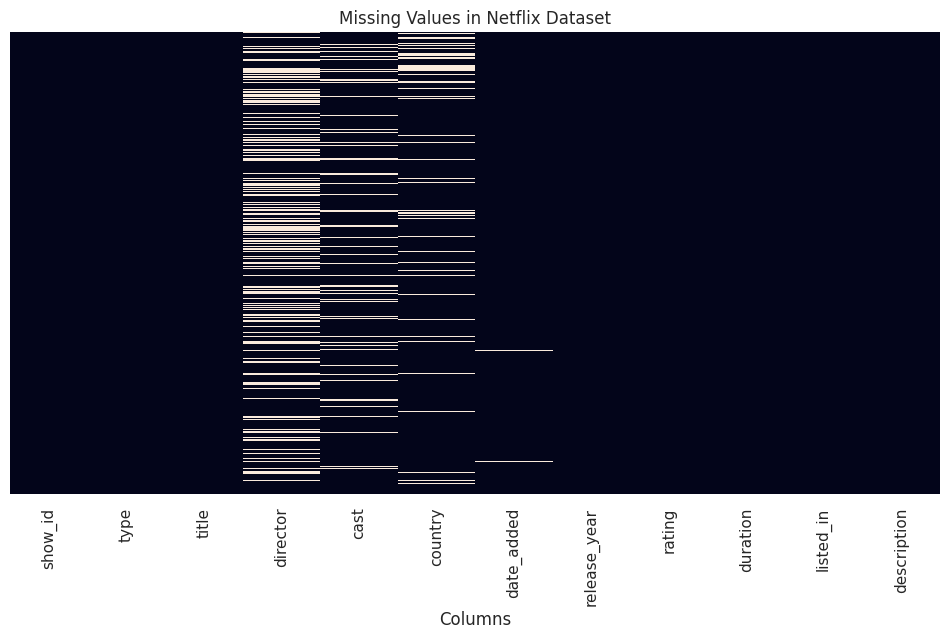

In [18]:
plt.figure(figsize=(12, 6))

sns.heatmap(df_original.isnull(), cbar=False, yticklabels=False)

plt.title("Missing Values in Netflix Dataset")
plt.xlabel("Columns")
plt.show()

In [20]:
cleaned_df = df_original.copy()

print("Original dataset preserved.")

Original dataset preserved.


In [22]:
# Fill missing director, cast and country values
cleaned_df['director'] = cleaned_df['director'].fillna('Unknown')
cleaned_df['cast'] = cleaned_df['cast'].fillna('Unknown')
cleaned_df['country'] = cleaned_df['country'].fillna('Unknown')

# Fill missing rating using mode
cleaned_df['rating'] = cleaned_df['rating'].fillna(
    cleaned_df['rating'].mode()[0]
)

# Fill missing date_added with Unknown
cleaned_df['date_added'] = cleaned_df['date_added'].fillna('Unknown')

# Remove records where duration is missing
cleaned_df = cleaned_df.dropna(subset=['duration'])

print("Missing values handled successfully!")

Missing values handled successfully!


/tmp/ipykernel_1907/1661543705.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cleaned_df['director'] = cleaned_df['director'].fillna('Unknown')
/tmp/ipykernel_1907/1661543705.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cleaned_df['cast'] = cleaned_df['cast'].fillna('Unknown')
/tmp/ipykernel_1907/1661543705.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation

In [23]:
print("Missing Values After Cleaning:")
display(cleaned_df.isnull().sum())

print("\nTotal Missing Values:",
      cleaned_df.isnull().sum().sum())

Missing Values After Cleaning:


,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,0
release_year,0
rating,0
duration,0



Total Missing Values: 0


In [24]:
print("Duplicate Records Before Removal:",
      cleaned_df.duplicated().sum())

cleaned_df = cleaned_df.drop_duplicates()

print("Duplicate Records After Removal:",
      cleaned_df.duplicated().sum())

Duplicate Records Before Removal: 0
Duplicate Records After Removal: 0


In [25]:
# Remove extra spaces from text columns
for col in cleaned_df.select_dtypes(include='object').columns:
    cleaned_df[col] = cleaned_df[col].str.strip()

# Standardise categorical values
cleaned_df['type'] = cleaned_df['type'].str.title()
cleaned_df['rating'] = cleaned_df['rating'].str.upper()

print("Category consistency checked!")

print("\nContent Types:")
print(cleaned_df['type'].value_counts())

print("\nRatings:")
print(cleaned_df['rating'].value_counts())

Category consistency checked!

Content Types:
type
Movie      6128
Tv Show    2676
Name: count, dtype: int64

Ratings:
rating
TV-MA       3211
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64


In [26]:
print("Summary Statistics:")
display(cleaned_df.describe())

Summary Statistics:


,release_year
count,8804.000000
mean,2014.180259
std,8.820647
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [27]:
print("Movies and TV Shows:")
display(cleaned_df['type'].value_counts())

print("Content Ratings:")
display(cleaned_df['rating'].value_counts())

print("Top 10 Release Years:")
display(cleaned_df['release_year'].value_counts().head(10))

Movies and TV Shows:


,count
type,
Movie,6128
Tv Show,2676


Content Ratings:


,count
rating,
TV-MA,3211
TV-14,2160
TV-PG,863
R,799
PG-13,490
TV-Y7,334
TV-Y,307
PG,287
TV-G,220


Top 10 Release Years:


,count
release_year,
2018,1147
2017,1031
2019,1030
2020,953
2016,902
2021,592
2015,559
2014,352
2013,288


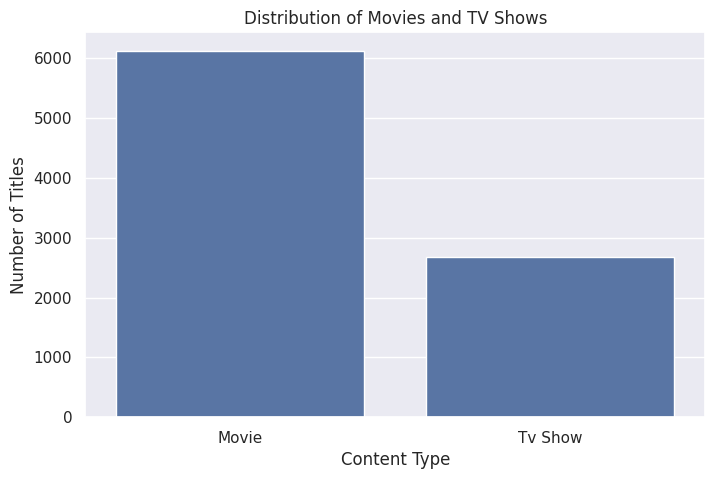

In [28]:
plt.figure(figsize=(8, 5))

sns.countplot(data=cleaned_df, x='type')

plt.title("Distribution of Movies and TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.show()

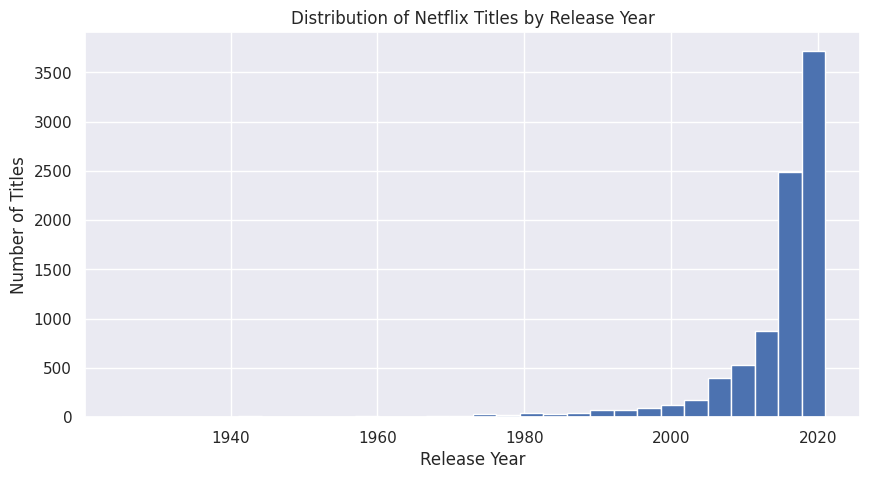

In [29]:
plt.figure(figsize=(10, 5))

plt.hist(cleaned_df['release_year'], bins=30)

plt.title("Distribution of Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.show()

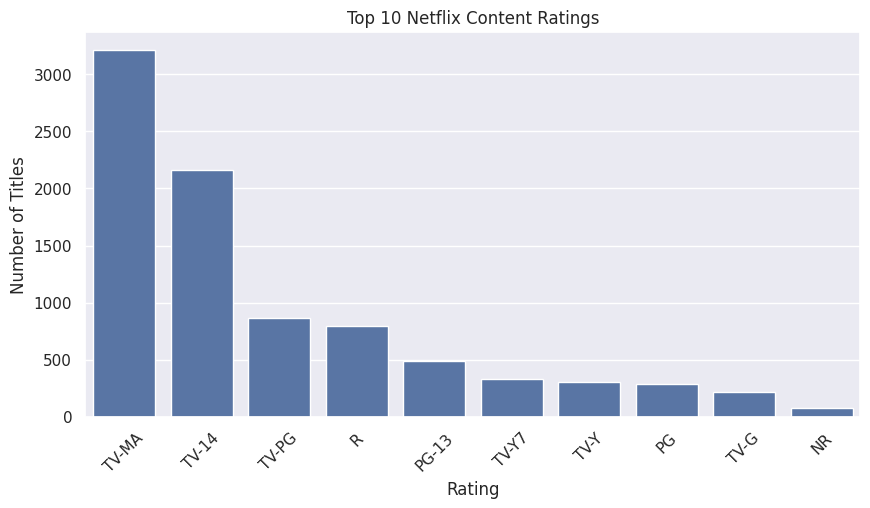

In [30]:
plt.figure(figsize=(10, 5))

top_ratings = cleaned_df['rating'].value_counts().head(10)

sns.barplot(x=top_ratings.index, y=top_ratings.values)

plt.title("Top 10 Netflix Content Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)

plt.show()

In [31]:
# Extract numerical duration and unit
duration_data = cleaned_df['duration'].str.extract(
    r'(\d+)\s*(min|Seasons?)'
)

cleaned_df['duration_value'] = pd.to_numeric(
    duration_data[0]
)

cleaned_df['duration_unit'] = duration_data[1]

# Create separate numerical columns
cleaned_df['duration_minutes'] = np.where(
    cleaned_df['duration_unit'] == 'min',
    cleaned_df['duration_value'],
    0
)

cleaned_df['duration_seasons'] = np.where(
    cleaned_df['duration_unit'].str.contains('Season', na=False),
    cleaned_df['duration_value'],
    0
)

# Remove original mixed-format duration columns
cleaned_df.drop(
    columns=['duration', 'duration_value', 'duration_unit'],
    inplace=True
)

display(cleaned_df.head())

,show_id,type,title,director,cast,country,date_added,release_year,rating,listed_in,description,duration_minutes,duration_seasons
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,"September 25, 2021",2020,PG-13,Documentaries,"As her father nears the end of his life, filmm...",90,0
1,s2,Tv Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",0,2
2,s3,Tv Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,"September 24, 2021",2021,TV-MA,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,0,1
3,s4,Tv Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,"September 24, 2021",2021,TV-MA,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",0,1
4,s5,Tv Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,0,2


In [32]:
# Convert categorical columns into numerical columns
encoded_df = pd.get_dummies(
    cleaned_df,
    columns=['type', 'rating'],
    dtype=int
)

print("Categorical Encoding Completed!")

display(encoded_df.head())

Categorical Encoding Completed!


,show_id,title,director,cast,country,date_added,release_year,listed_in,description,duration_minutes,duration_seasons,type_Movie,type_Tv Show,rating_G,rating_NC-17,rating_NR,rating_PG,rating_PG-13,rating_R,rating_TV-14,rating_TV-G,rating_TV-MA,rating_TV-PG,rating_TV-Y,rating_TV-Y7,rating_TV-Y7-FV,rating_UR
0,s1,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,"September 25, 2021",2020,Documentaries,"As her father nears the end of his life, filmm...",90,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
1,s2,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",0,2,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0
2,s3,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,"September 24, 2021",2021,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,0,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0
3,s4,Jailbirds New Orleans,Unknown,Unknown,Unknown,"September 24, 2021",2021,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",0,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0
4,s5,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,0,2,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0


In [33]:
scaler = StandardScaler()

# Select numerical features
features_to_scale = [
    'release_year',
    'duration_minutes',
    'duration_seasons'
]

# Apply standardisation
encoded_df[features_to_scale] = scaler.fit_transform(
    encoded_df[features_to_scale]
)

print("Numerical Scaling Completed!")

display(encoded_df.head())

Numerical Scaling Completed!


,show_id,title,director,cast,country,date_added,release_year,listed_in,description,duration_minutes,duration_seasons,type_Movie,type_Tv Show,rating_G,rating_NC-17,rating_NR,rating_PG,rating_PG-13,rating_R,rating_TV-14,rating_TV-G,rating_TV-MA,rating_TV-PG,rating_TV-Y,rating_TV-Y7,rating_TV-Y7-FV,rating_UR
0,s1,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,"September 25, 2021",0.659824,Documentaries,"As her father nears the end of his life, filmm...",0.401546,-0.450159,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
1,s2,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",0.773200,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",-1.345188,1.228096,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0
2,s3,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,"September 24, 2021",0.773200,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,-1.345188,0.388968,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0
3,s4,Jailbirds New Orleans,Unknown,Unknown,Unknown,"September 24, 2021",0.773200,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",-1.345188,0.388968,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0
4,s5,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",0.773200,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,-1.345188,1.228096,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0


In [34]:
print("Mean After Scaling:")

display(encoded_df[features_to_scale].mean())

print("\nStandard Deviation After Scaling:")

display(encoded_df[features_to_scale].std())

Mean After Scaling:


,0
release_year,1.885311e-15
duration_minutes,-3.873927e-17
duration_seasons,1.291309e-17



Standard Deviation After Scaling:


,0
release_year,1.000057
duration_minutes,1.000057
duration_seasons,1.000057


In [35]:
print("Final Dataset Shape:", encoded_df.shape)

print("\nRemaining Missing Values:")
print(encoded_df.isnull().sum().sum())

print("\nRemaining Duplicate Records:")
print(encoded_df.duplicated().sum())

print("\nFinal Dataset Sample:")
display(encoded_df.head(10))

Final Dataset Shape: (8804, 27)

Remaining Missing Values:
0

Remaining Duplicate Records:
0

Final Dataset Sample:


,show_id,title,director,cast,country,date_added,release_year,listed_in,description,duration_minutes,duration_seasons,type_Movie,type_Tv Show,rating_G,rating_NC-17,rating_NR,rating_PG,rating_PG-13,rating_R,rating_TV-14,rating_TV-G,rating_TV-MA,rating_TV-PG,rating_TV-Y,rating_TV-Y7,rating_TV-Y7-FV,rating_UR
0,s1,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,"September 25, 2021",0.659824,Documentaries,"As her father nears the end of his life, filmm...",0.401546,-0.450159,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
1,s2,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",0.773200,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",-1.345188,1.228096,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0
2,s3,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,"September 24, 2021",0.773200,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,-1.345188,0.388968,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0
3,s4,Jailbirds New Orleans,Unknown,Unknown,Unknown,"September 24, 2021",0.773200,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",-1.345188,0.388968,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0
4,s5,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",0.773200,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,-1.345188,1.228096,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0
5,s6,Midnight Mass,Mike Flanagan,"Kate Siegel, Zach Gilford, Hamish Linklater, H...",Unknown,"September 24, 2021",0.773200,"TV Dramas, TV Horror, TV Mysteries",The arrival of a charismatic young priest brin...,-1.345188,0.388968,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0
6,s7,My Little Pony: A New Generation,"Robert Cullen, José Luis Ucha","Vanessa Hudgens, Kimiko Glenn, James Marsden, ...",Unknown,"September 24, 2021",0.773200,Children & Family Movies,Equestria's divided. But a bright-eyed hero be...,0.420955,-0.450159,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
7,s8,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...","United States, Ghana, Burkina Faso, United Kin...","September 24, 2021",-2.401350,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model s...",1.080832,-0.450159,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
8,s9,The Great British Baking Show,Andy Devonshire,"Mel Giedroyc, Sue Perkins, Mary Berry, Paul Ho...",United Kingdom,"September 24, 2021",0.773200,"British TV Shows, Reality TV",A talented batch of amateur bakers face off in...,-1.345188,7.101985,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0
9,s10,The Starling,Theodore Melfi,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...",United States,"September 24, 2021",0.773200,"Comedies, Dramas",A woman adjusting to life after a loss contend...,0.673261,-0.450159,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0


In [36]:
encoded_df.to_csv(
    'Netflix_Prepared_Dataset.csv',
    index=False
)

print("Prepared Dataset Saved Successfully!")

Prepared Dataset Saved Successfully!


In [37]:
from google.colab import files

files.download('Netflix_Prepared_Dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>